# 17. Write a python program to perform basic morphological operations (Erosion, Dilation, Opening, Closing).

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [10]:
img = cv2.imread("image.jpeg", cv2.IMREAD_GRAYSCALE)
_, binary = cv2.threshold(
    img,
    127,
    255,
    cv2.THRESH_BINARY
)

In [11]:
binary

array([[  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0],
       ...,
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255]], shape=(148, 165), dtype=uint8)

In [12]:
rows, cols = binary.shape

In [13]:
# Structuring element (3x3)
kernel = np.ones((3, 3), dtype=np.uint8)

In [ ]:
def erosion(img):
    erosion = np.zeros(img.shape, dtype=np.uint8)
    for i in range(1, img.shape[0]-1):
        for j in range(1, img.shape[1]-1):
            if np.all(img[i-1:i+2, j-1:j+2] == 255):
                erosion[i][j] = 255
    return erosion

def dilation(img):
    dilation = np.zeros(img.shape, dtype=np.uint8)
    for i in range(1, img.shape[0]-1):
        for j in range(1, img.shape[1]-1):
            if np.any(img[i-1:i+2, j-1:j+2] == 255):
                dilation[i][j] = 255
    return dilation

In [15]:
erode_img = erosion(binary)
dilate_img = dilation(binary)

open_img = dilation(erode_img)
close_img = erosion(dilate_img)

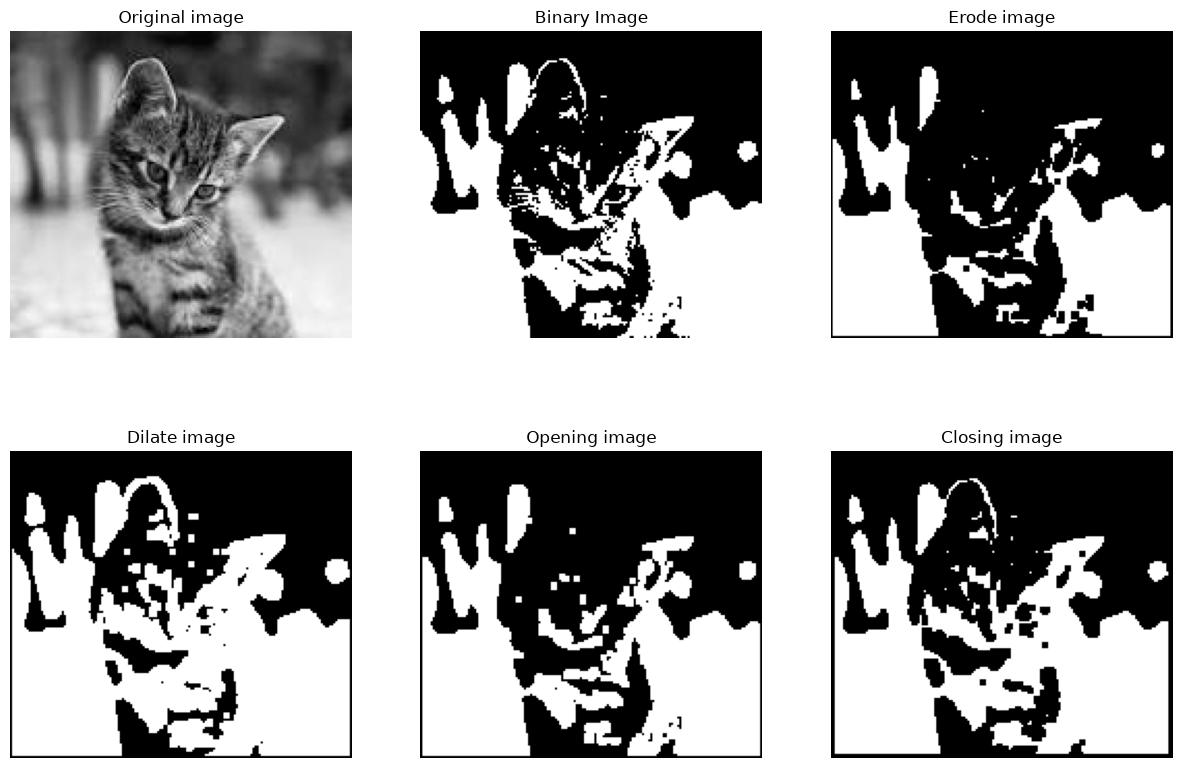

In [17]:
imgs = [img, binary, erode_img, dilate_img, open_img,close_img]
title = ["Original image", "Binary Image", "Erode image", "Dilate image", "Opening image", "Closing image"]
plt.figure(figsize=(15, 10))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(imgs[i], cmap="gray")
    plt.title(title[i])
    plt.axis("off")